In [607]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mode
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster
from sklearn.preprocessing import StandardScaler, MinMaxScaler


sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,number_of_hadm,gender,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,icd_binary_scaled
0,10000980,2,1,75.0,169.0,69.0,1.0,0.0,0.0,7.0,163.0,0.0,0.0,0.0,0.666669
1,10002013,1,1,69.0,40.0,15.0,0.0,0.0,0.0,2.0,395.0,0.0,0.0,0.0,0.000001
2,10002155,1,1,69.0,276.0,106.0,4.0,0.0,0.0,8.0,140.0,0.0,0.0,0.0,0.000001
3,10004457,1,0,66.0,21.0,6.0,0.0,0.0,0.0,0.0,92.0,0.0,0.0,0.0,0.000650
4,10007058,1,0,48.0,112.0,42.0,2.0,0.0,0.0,2.0,111.0,0.0,0.0,0.0,0.000001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,1,1,71.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166666
4379,19998597,1,1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000080
4380,19998598,1,1,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.083332
4381,19998599,1,0,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000039


In [608]:
#Convert subject_id to string
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Scale with min-max scaler, but not icd_binary_scaled
numeric_cols = profile_df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols.remove('icd_binary_scaled') # Exclude icd_binary_scaled since it's already scaled
numeric_cols.remove('gender')

scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)

# Re adding icd_binary_scaled to X
X = np.hstack((X, profile_df[['icd_binary_scaled']].values))

# Hierarchical clustering

In [609]:
# Hierarchical Clustering with Ward's method
data_dist = pdist(X, metric='euclidean')
data_link = linkage(data_dist, method='ward', metric='euclidean')

k=2: Silhouette=0.6089, CH=2204.94
k=3: Silhouette=0.5289, CH=3394.61
k=4: Silhouette=0.5322, CH=2776.58
k=5: Silhouette=0.5362, CH=2345.55
k=6: Silhouette=0.2981, CH=2117.60
k=7: Silhouette=0.2674, CH=1911.34
k=8: Silhouette=0.2583, CH=1772.76
k=9: Silhouette=0.2599, CH=1679.07
k=10: Silhouette=0.2598, CH=1581.09
k=11: Silhouette=0.2656, CH=1500.05
k=12: Silhouette=0.2680, CH=1433.86
k=13: Silhouette=0.2687, CH=1380.29
k=14: Silhouette=0.2727, CH=1336.44
k=15: Silhouette=0.2786, CH=1295.52
k=16: Silhouette=0.2668, CH=1259.55
k=17: Silhouette=0.2648, CH=1227.07
k=18: Silhouette=0.2662, CH=1199.32
k=19: Silhouette=0.2658, CH=1170.31

Cophenetic Correlation Coefficient: 0.7727


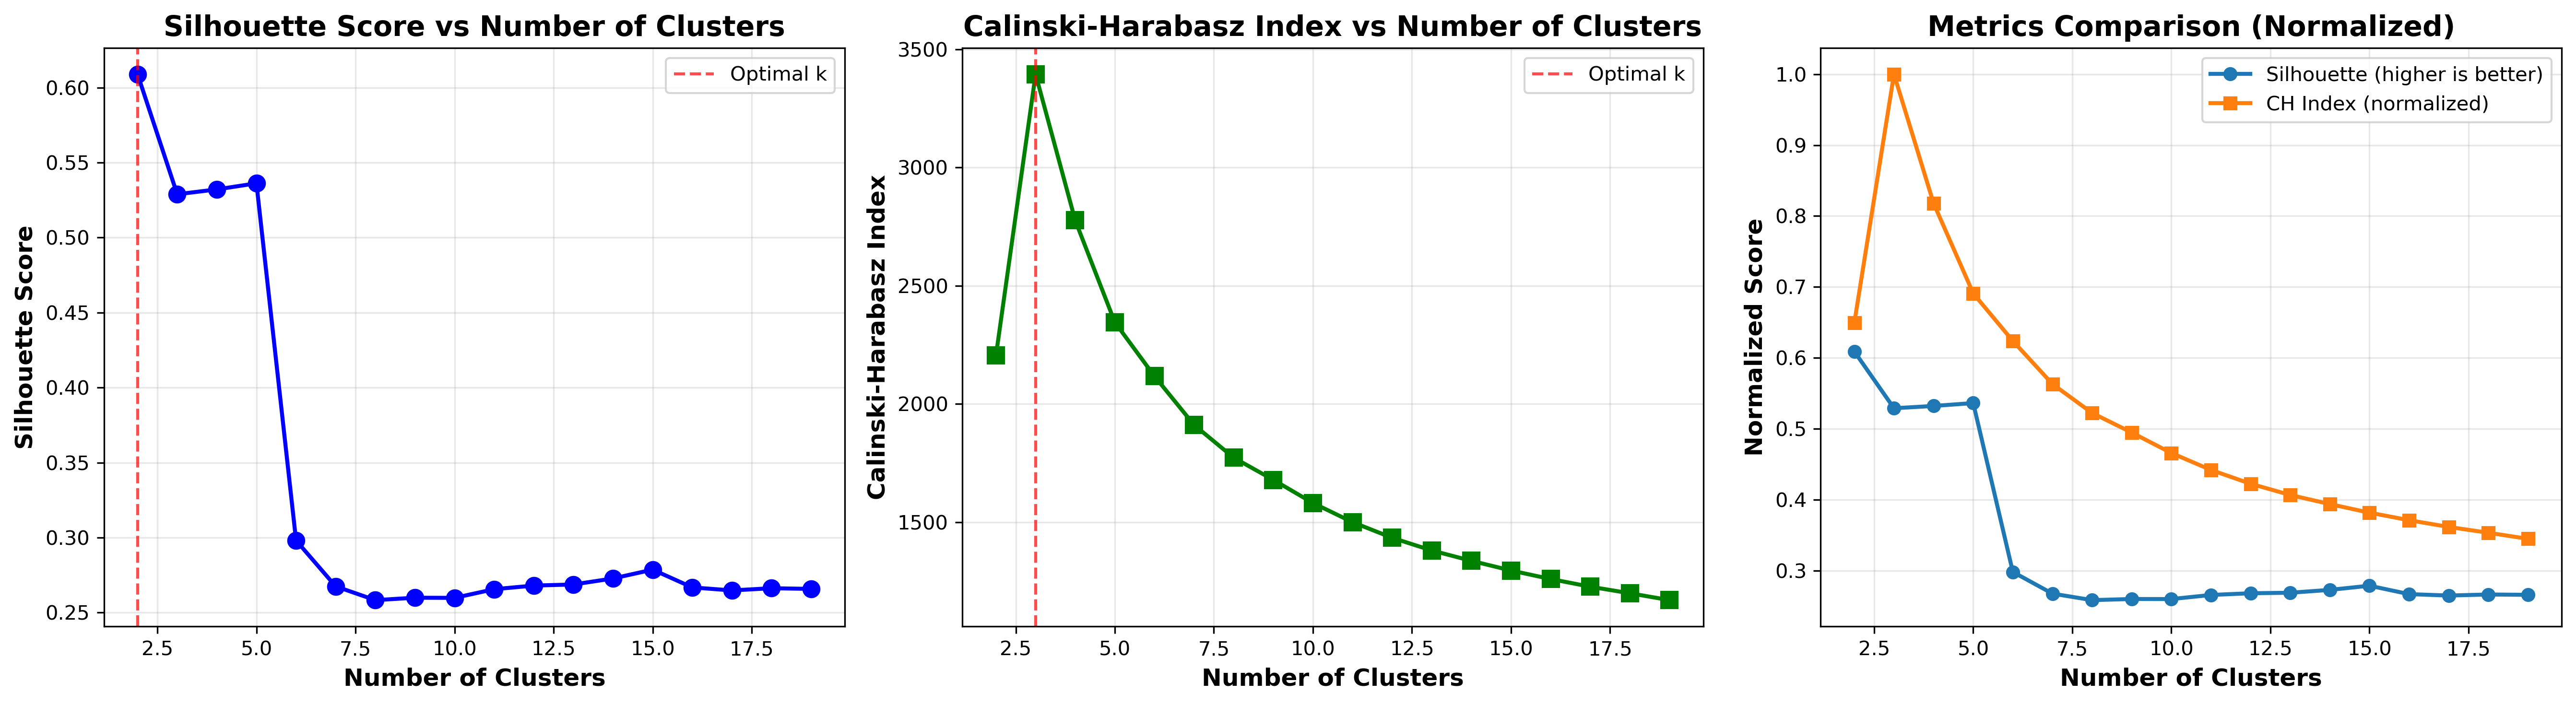


OPTIMAL NUMBER OF CLUSTERS BY DIFFERENT METRICS:
Silhouette Score: k = 2 (score = 0.6089)
Calinski-Harabasz: k = 3 (score = 3394.61)

Recommended optimal k: 2 (based on Silhouette Score)


In [610]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import cophenet

# Test different thresholds/number of clusters
silhouette_scores = []
calinski_harabasz_scores = []
k_range = range(2, 20)  # Test 2 to 20 clusters

for k in k_range:
    cluster_labels = fcluster(data_link, t=k, criterion='maxclust')
    
    # Use the same data (X) that was used for clustering
    sil_score = silhouette_score(X, cluster_labels, metric='euclidean')
    ch_score = calinski_harabasz_score(X, cluster_labels)
    
    silhouette_scores.append(sil_score)
    calinski_harabasz_scores.append(ch_score)
    
    print(f"k={k}: Silhouette={sil_score:.4f}, CH={ch_score:.2f}")

# Calculate the Cophenetic Correlation Coefficient (independent of k)
coph_corr, coph_dists = cophenet(data_link, data_dist)
print(f"\nCophenetic Correlation Coefficient: {coph_corr:.4f}")

# Create subplots for metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=300)

# Plot 1: Silhouette Score
axes[0].plot(k_range, silhouette_scores, marker='o', linewidth=2, markersize=8, color='blue')
axes[0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
axes[0].set_title('Silhouette Score vs Number of Clusters', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(x=k_range[np.argmax(silhouette_scores)], color='red', linestyle='--', alpha=0.7, label='Optimal k')
axes[0].legend()

# Plot 2: Calinski-Harabasz Index
axes[1].plot(k_range, calinski_harabasz_scores, marker='s', linewidth=2, markersize=8, color='green')
axes[1].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Calinski-Harabasz Index', fontsize=12, fontweight='bold')
axes[1].set_title('Calinski-Harabasz Index vs Number of Clusters', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].axvline(x=k_range[np.argmax(calinski_harabasz_scores)], color='red', linestyle='--', alpha=0.7, label='Optimal k')
axes[1].legend()

# Plot 3: Comparison
axes[2].plot(k_range, np.array(silhouette_scores), marker='o', linewidth=2, label='Silhouette (higher is better)')
axes[2].plot(k_range, np.array(calinski_harabasz_scores) / np.max(calinski_harabasz_scores), 
                marker='s', linewidth=2, label='CH Index (normalized)')
axes[2].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Normalized Score', fontsize=12, fontweight='bold')
axes[2].set_title('Metrics Comparison (Normalized)', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

# Find optimal k based on different metrics
optimal_k_silhouette = k_range[np.argmax(silhouette_scores)]
optimal_k_ch = k_range[np.argmax(calinski_harabasz_scores)]

print(f"\n{'='*60}")
print(f"OPTIMAL NUMBER OF CLUSTERS BY DIFFERENT METRICS:")
print(f"{'='*60}")
print(f"Silhouette Score: k = {optimal_k_silhouette} (score = {max(silhouette_scores):.4f})")
print(f"Calinski-Harabasz: k = {optimal_k_ch} (score = {max(calinski_harabasz_scores):.2f})")
print(f"{'='*60}")

# Use the most common optimal k or prioritize silhouette
optimal_k = optimal_k_silhouette
print(f"\nRecommended optimal k: {optimal_k} (based on Silhouette Score)")

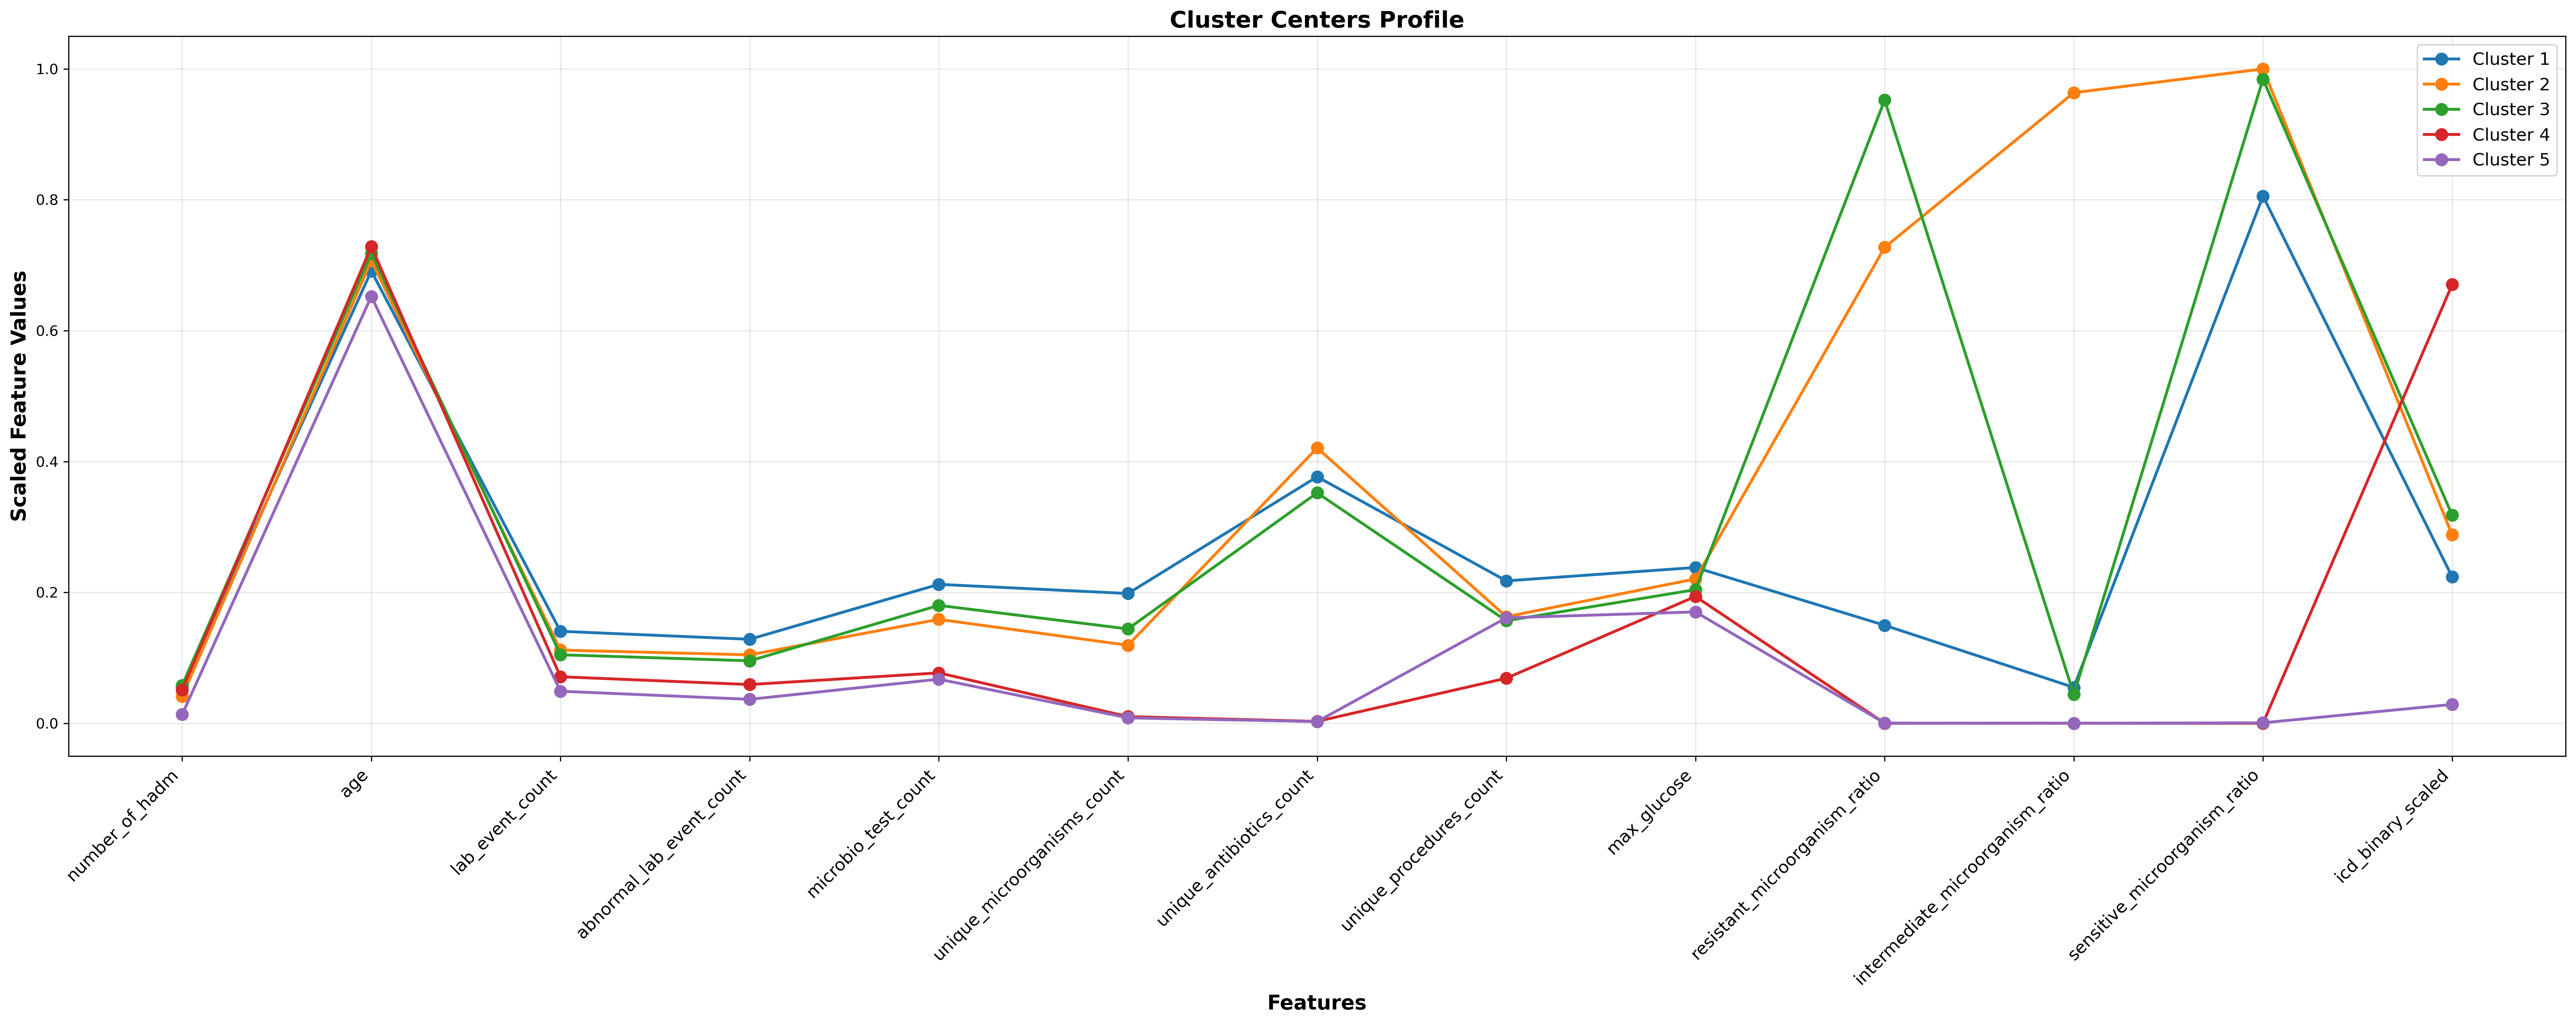

In [611]:
used_k = 5
# Get cluster labels
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')

# Add cluster labels to the dataframe
profile_df['cluster'] = cluster_labels

# Compute cluster centers (mean of each feature per cluster)
# Use the scaled data X and the numeric column names
feature_names = numeric_cols + ['icd_binary_scaled']
X_with_labels = np.column_stack([X, cluster_labels])

# Calculate centers for each cluster
centers = []
for cluster_id in range(1, used_k + 1):
    cluster_mask = cluster_labels == cluster_id
    cluster_center = X[cluster_mask].mean(axis=0)
    centers.append(cluster_center)

centers = np.array(centers)

# Plot cluster centers
plt.figure(figsize=(25, 10), dpi=300)
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label='Cluster %s' % (i + 1), linewidth=2, markersize=8)

plt.tick_params(axis='both', which='major', labelsize=10)
plt.xticks(range(len(feature_names)), feature_names, fontsize=12, rotation=45, ha='right')
plt.xlabel('Features', fontsize=14, fontweight='bold')
plt.ylabel('Scaled Feature Values', fontsize=14, fontweight='bold')
plt.title('Cluster Centers Profile', fontsize=16, fontweight='bold')
plt.legend(fontsize=12, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

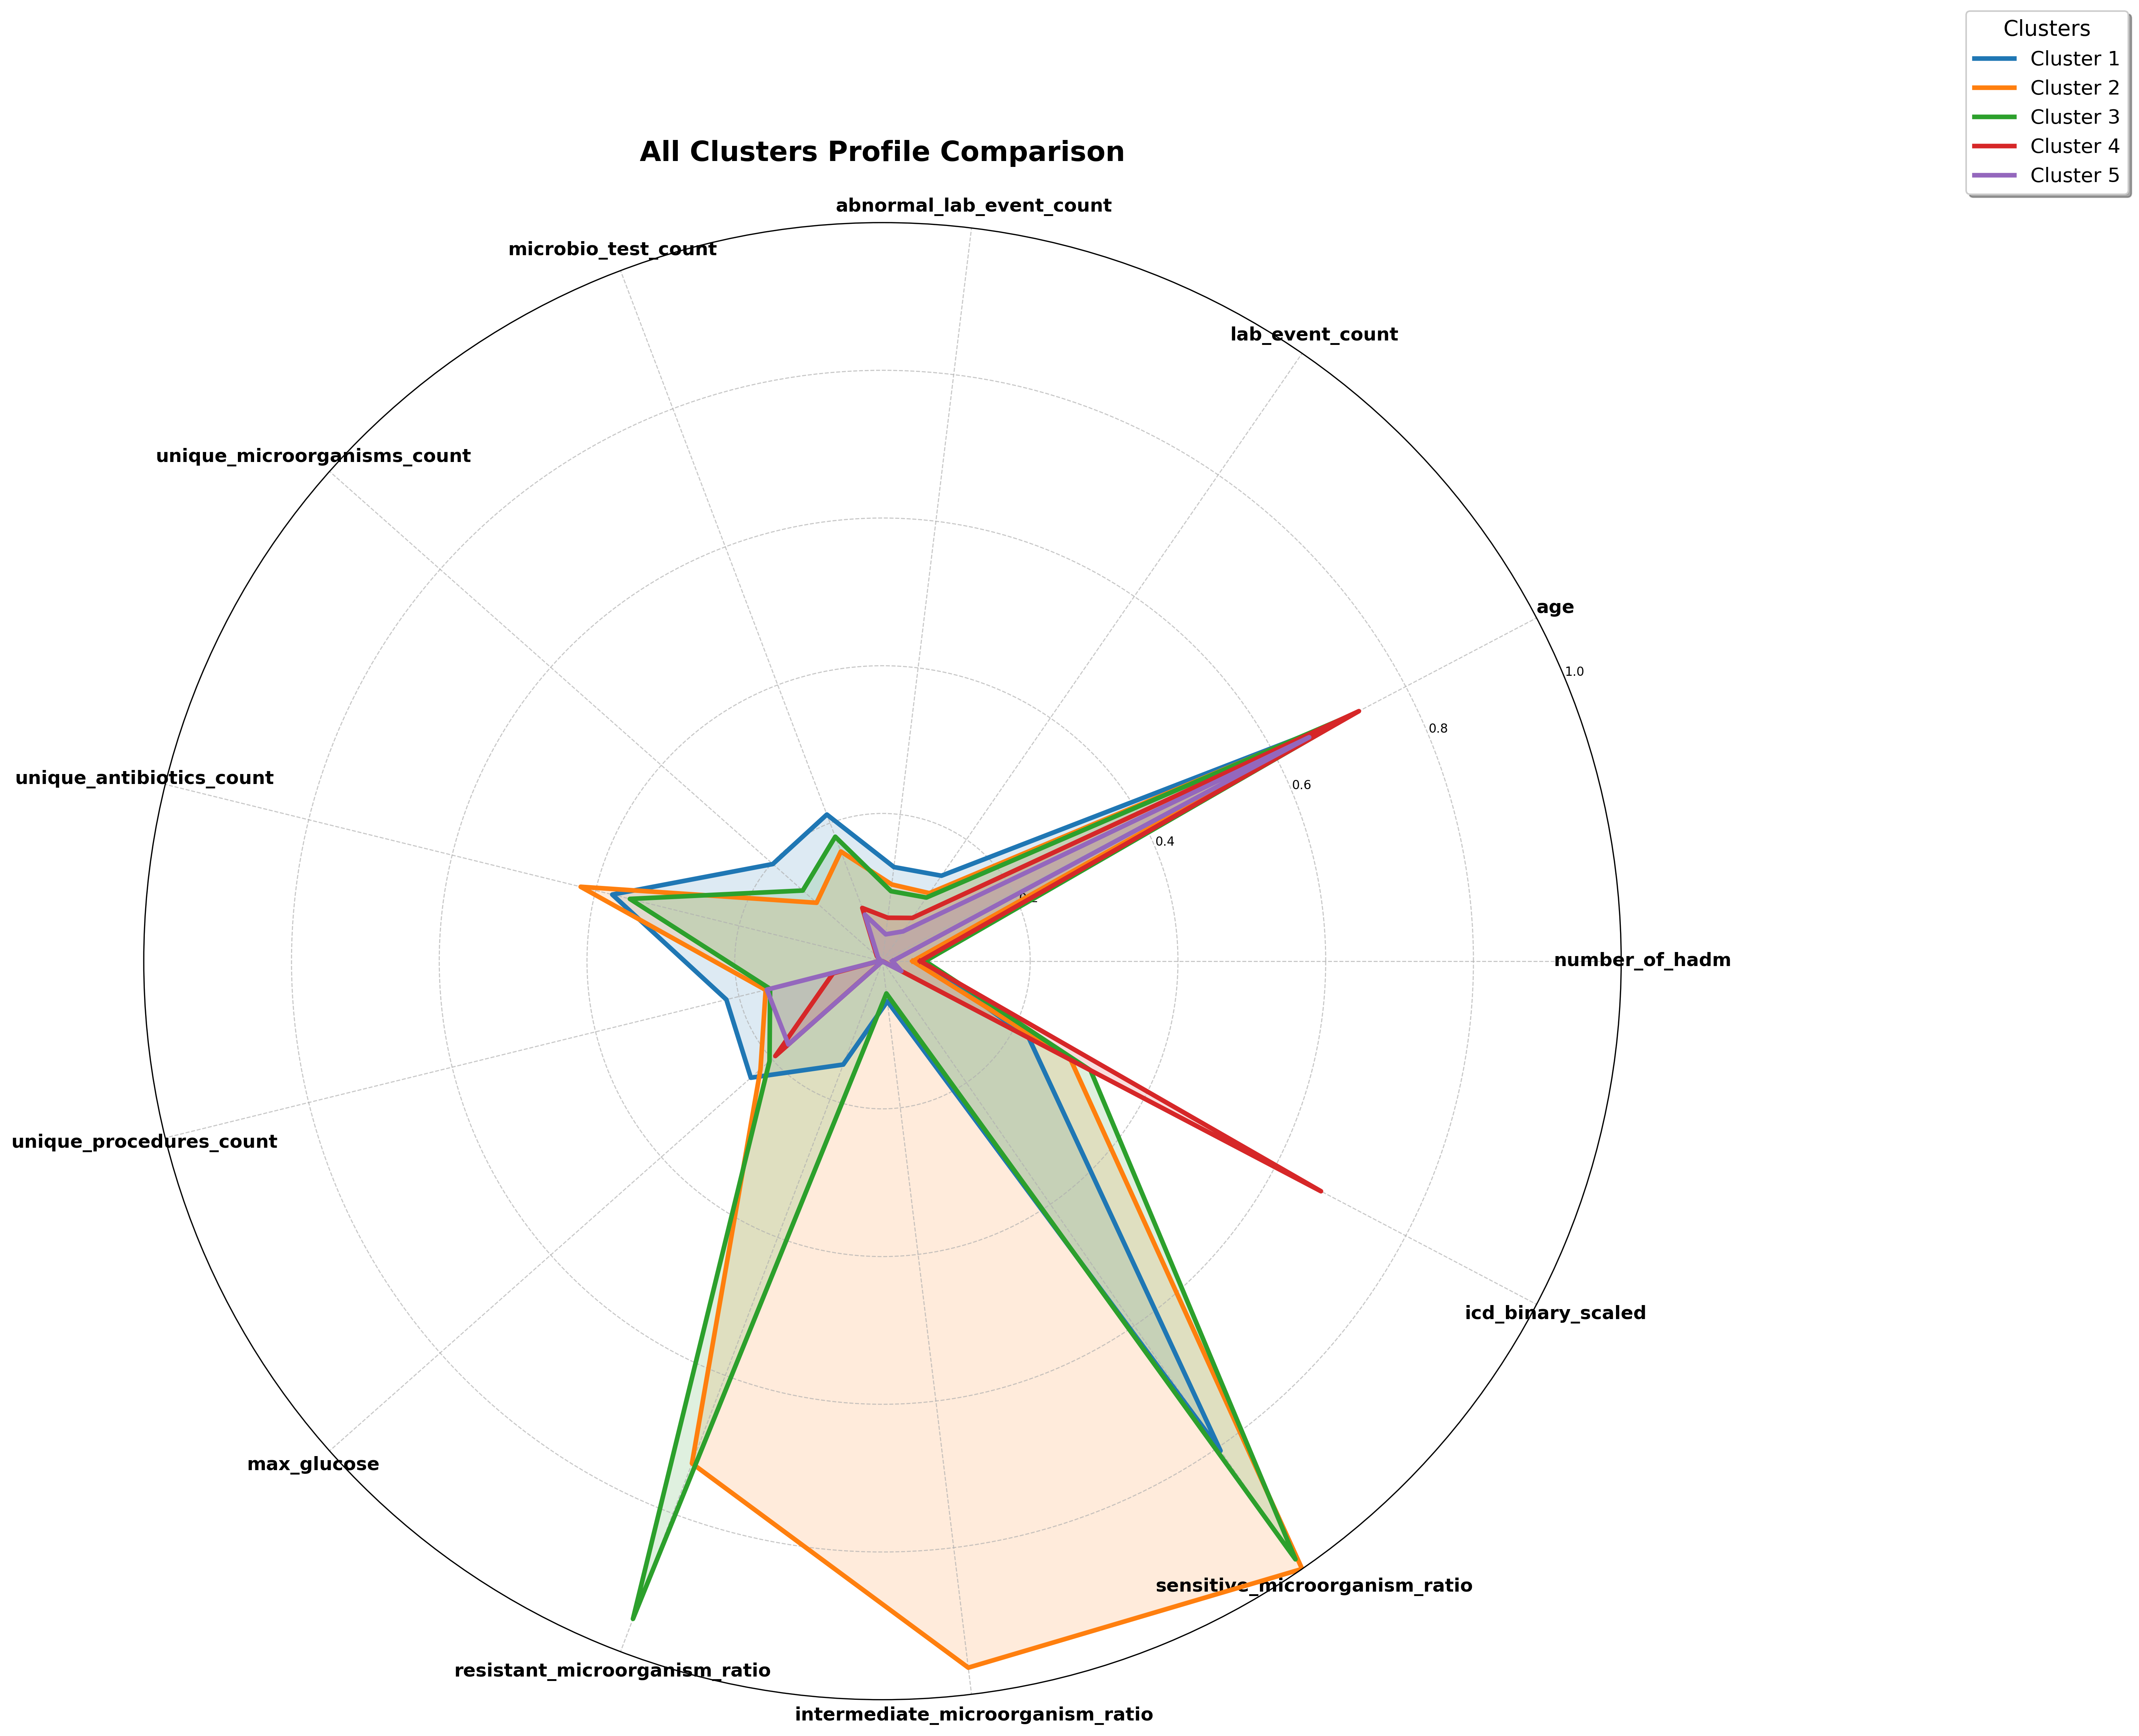

In [612]:
from math import pi
from matplotlib.colors import ListedColormap

# Number of features
N = len(feature_names)

# Get number of clusters
n_clusters = len(centers)

# Create a color palette with exactly n_clusters colors
if n_clusters <= 10:
    colors_list = plt.cm.tab10(np.linspace(0, 1, 10))[:n_clusters]
else:
    colors_list = plt.cm.tab20(np.linspace(0, 1, 20))[:n_clusters]

# Create ONE radar plot with all clusters overlapped
fig = plt.figure(figsize=(20,20), dpi=300)
ax = plt.subplot(111, polar=True)

# Calculate angles for each feature
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Complete the circle

# Draw one axis per variable and add labels with better visibility
plt.xticks(angles[:-1], feature_names, color='black', size=12, fontweight='bold')

# Plot all clusters on the same radar chart
for i in range(len(centers)):
    values = centers[i].tolist()
    values += values[:1]  # Complete the circle
    
    # Plot data with unique color for each cluster
    ax.plot(angles, values, linewidth=3, linestyle='solid', 
            label=f'Cluster {i+1}', color=colors_list[i])
    
    # Fill area with the same color
    ax.fill(angles, values, alpha=0.15, color=colors_list[i])

# Set y-axis limits
ax.set_ylim(0, 1)

# Increase y-axis tick label size
ax.tick_params(axis='y', labelsize=8)

# Add title
ax.set_title('All Clusters Profile Comparison', size=18, fontweight='bold', pad=40)

# Add legend
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=13, 
           title='Clusters', title_fontsize=14, frameon=True, shadow=True)

# Add grid
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)

plt.tight_layout()
plt.show()


Number of subjects in each cluster:
Cluster 1: 195 subjects
Cluster 2: 55 subjects
Cluster 3: 121 subjects
Cluster 4: 1159 subjects
Cluster 5: 2853 subjects


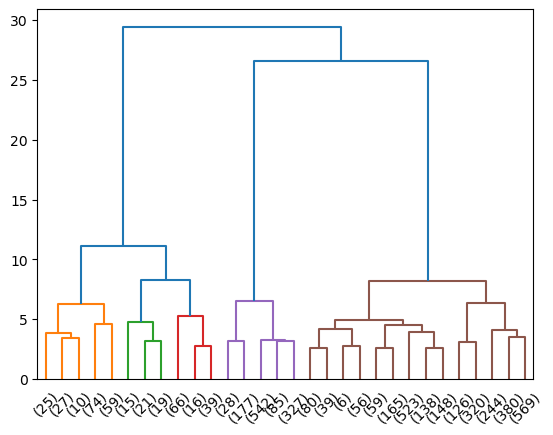

In [613]:
# Calculate the threshold based on optimal_k
# Get the linkage distances
distances = data_link[:, 2]
# Find the threshold that gives us optimal_k clusters
threshold_index = len(data_link) - used_k + 1
color_threshold = data_link[threshold_index, 2] if threshold_index < len(data_link) else data_link[-1, 2]

res = dendrogram(
    data_link, 
    color_threshold=color_threshold,
    truncate_mode='lastp',
)

# Print the number of subjects in each cluster
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
profile_df['cluster'] = cluster_labels
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print("\nNumber of subjects in each cluster:")
for cluster_id, count in cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} subjects")    


# Plots

## Age vs Number of admission scatter plot

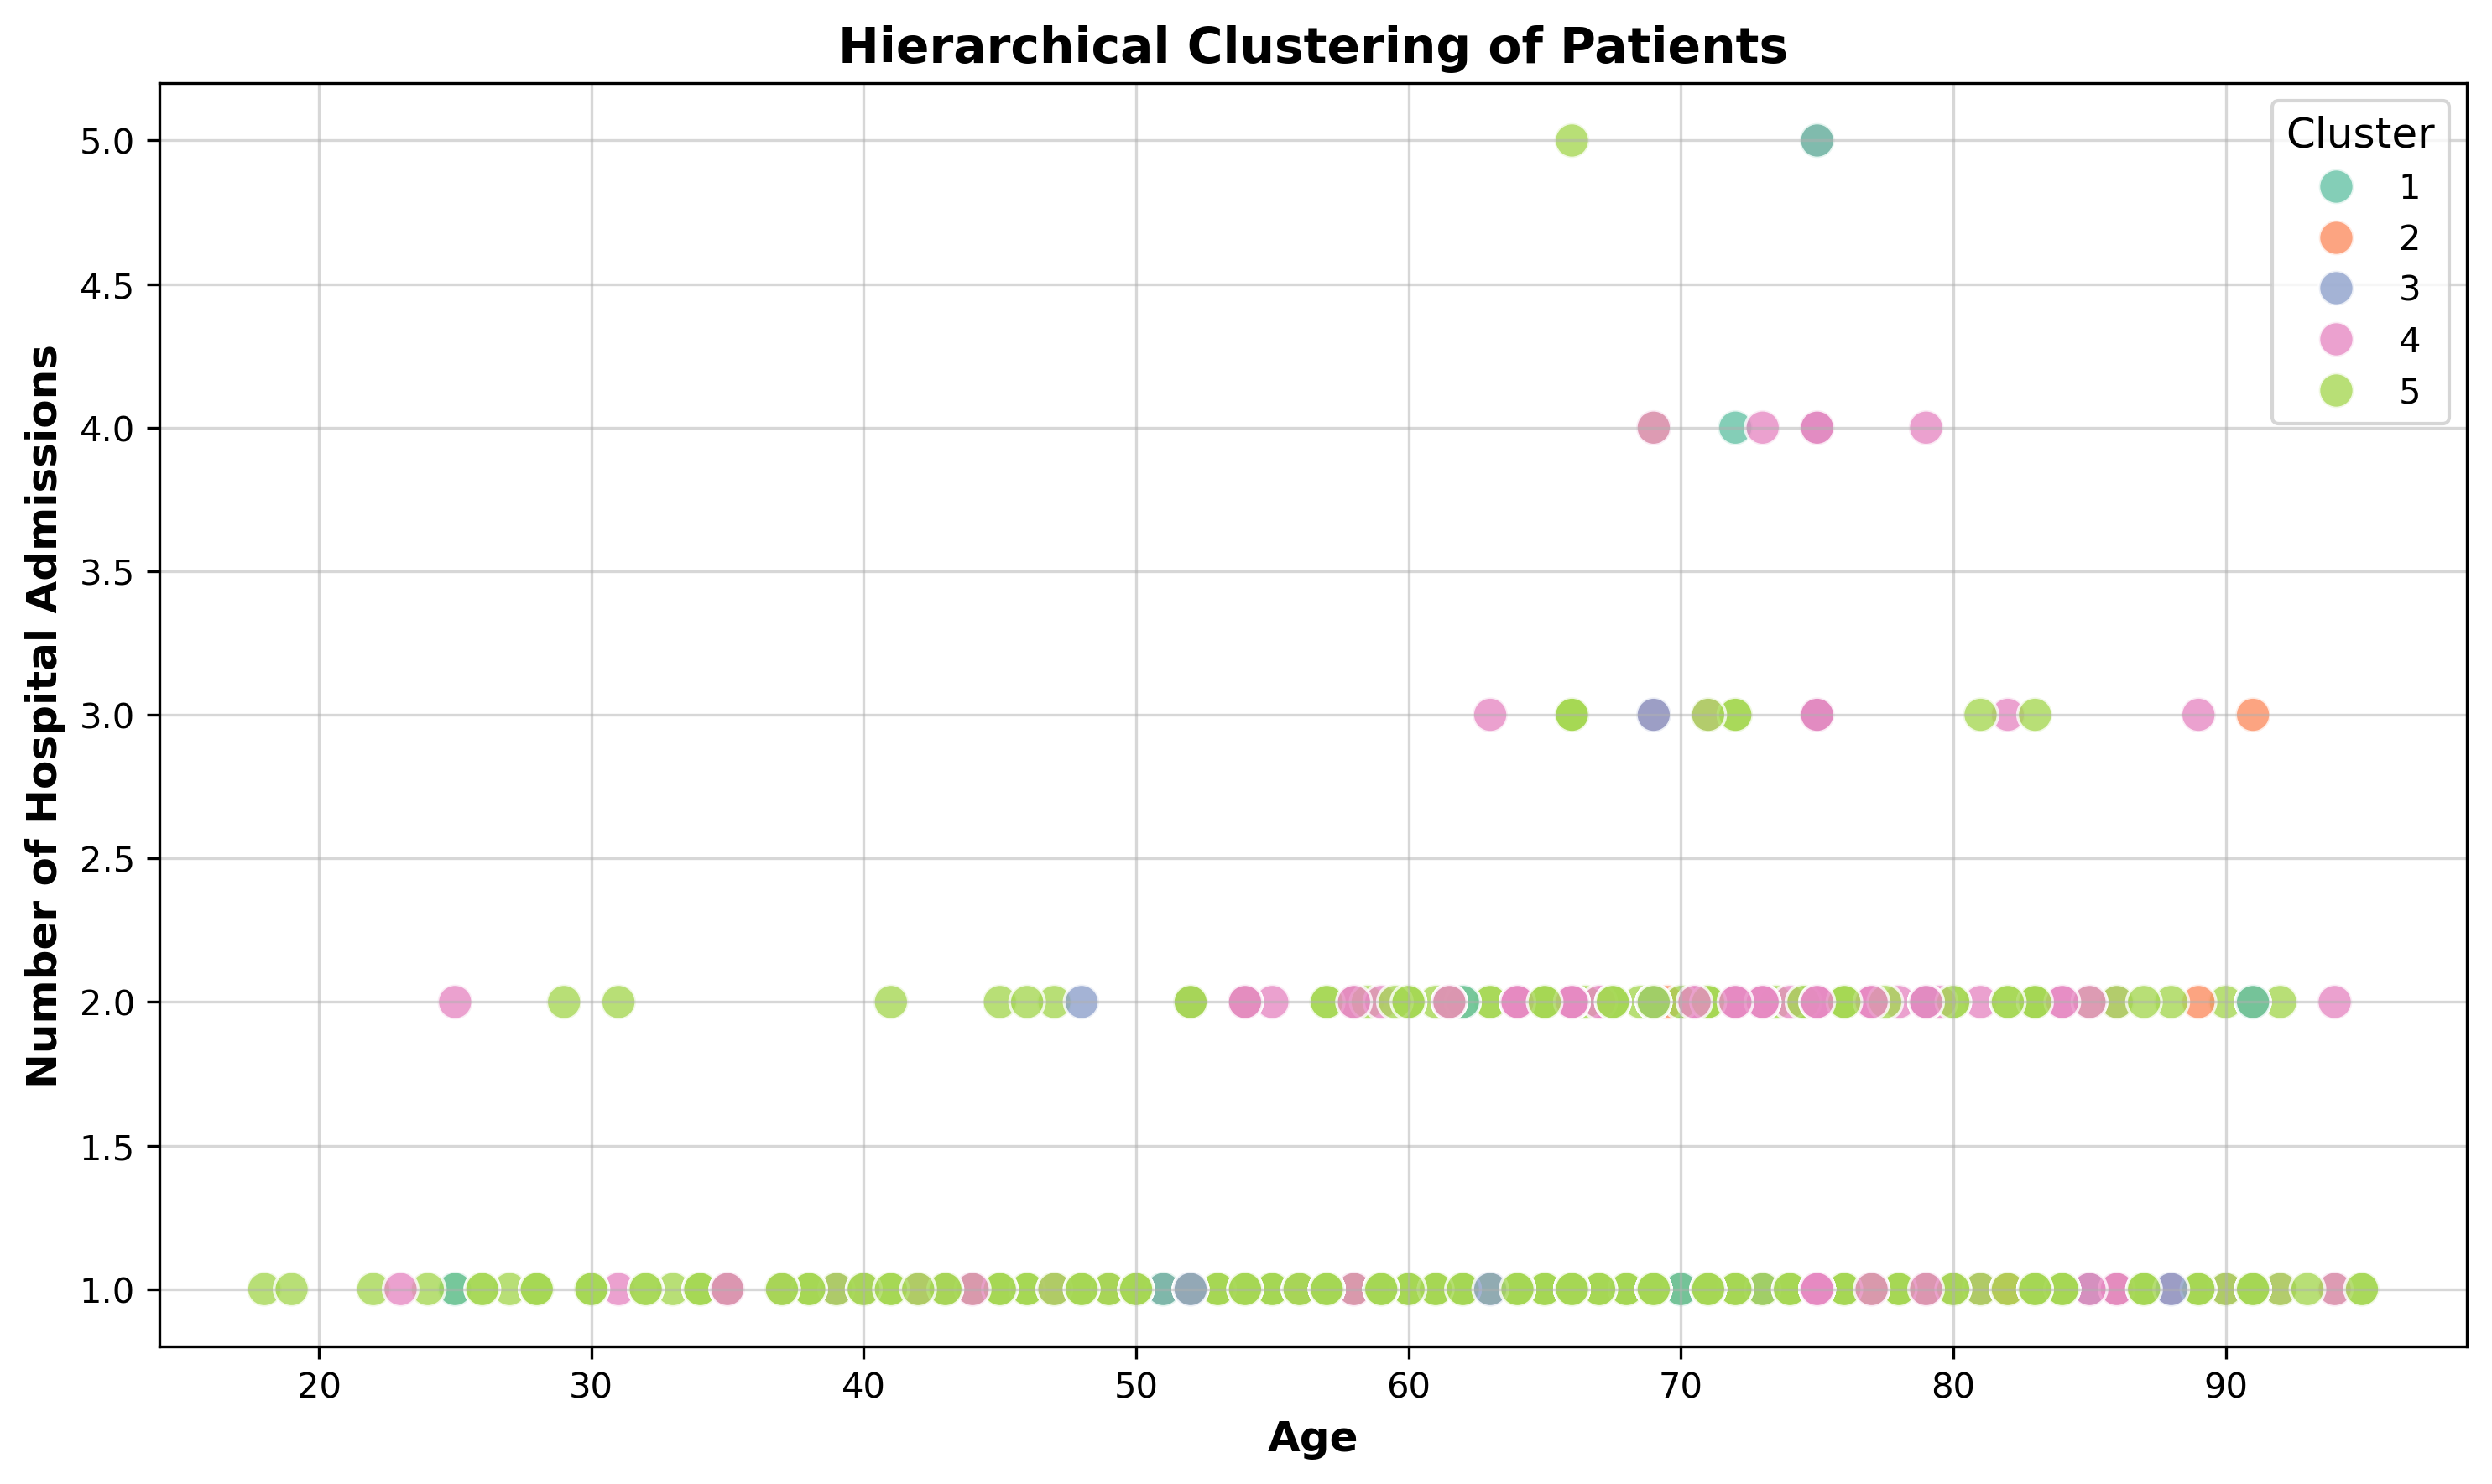

In [614]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['age'], y=profile_df['number_of_hadm'], hue=cluster_labels, palette='Set2', s=100, alpha=0.8)
plt.xlabel('Age', fontsize=12, fontweight='bold')
plt.ylabel('Number of Hospital Admissions', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show() 

## Number of organism vs Number of antibiotic scatter plot

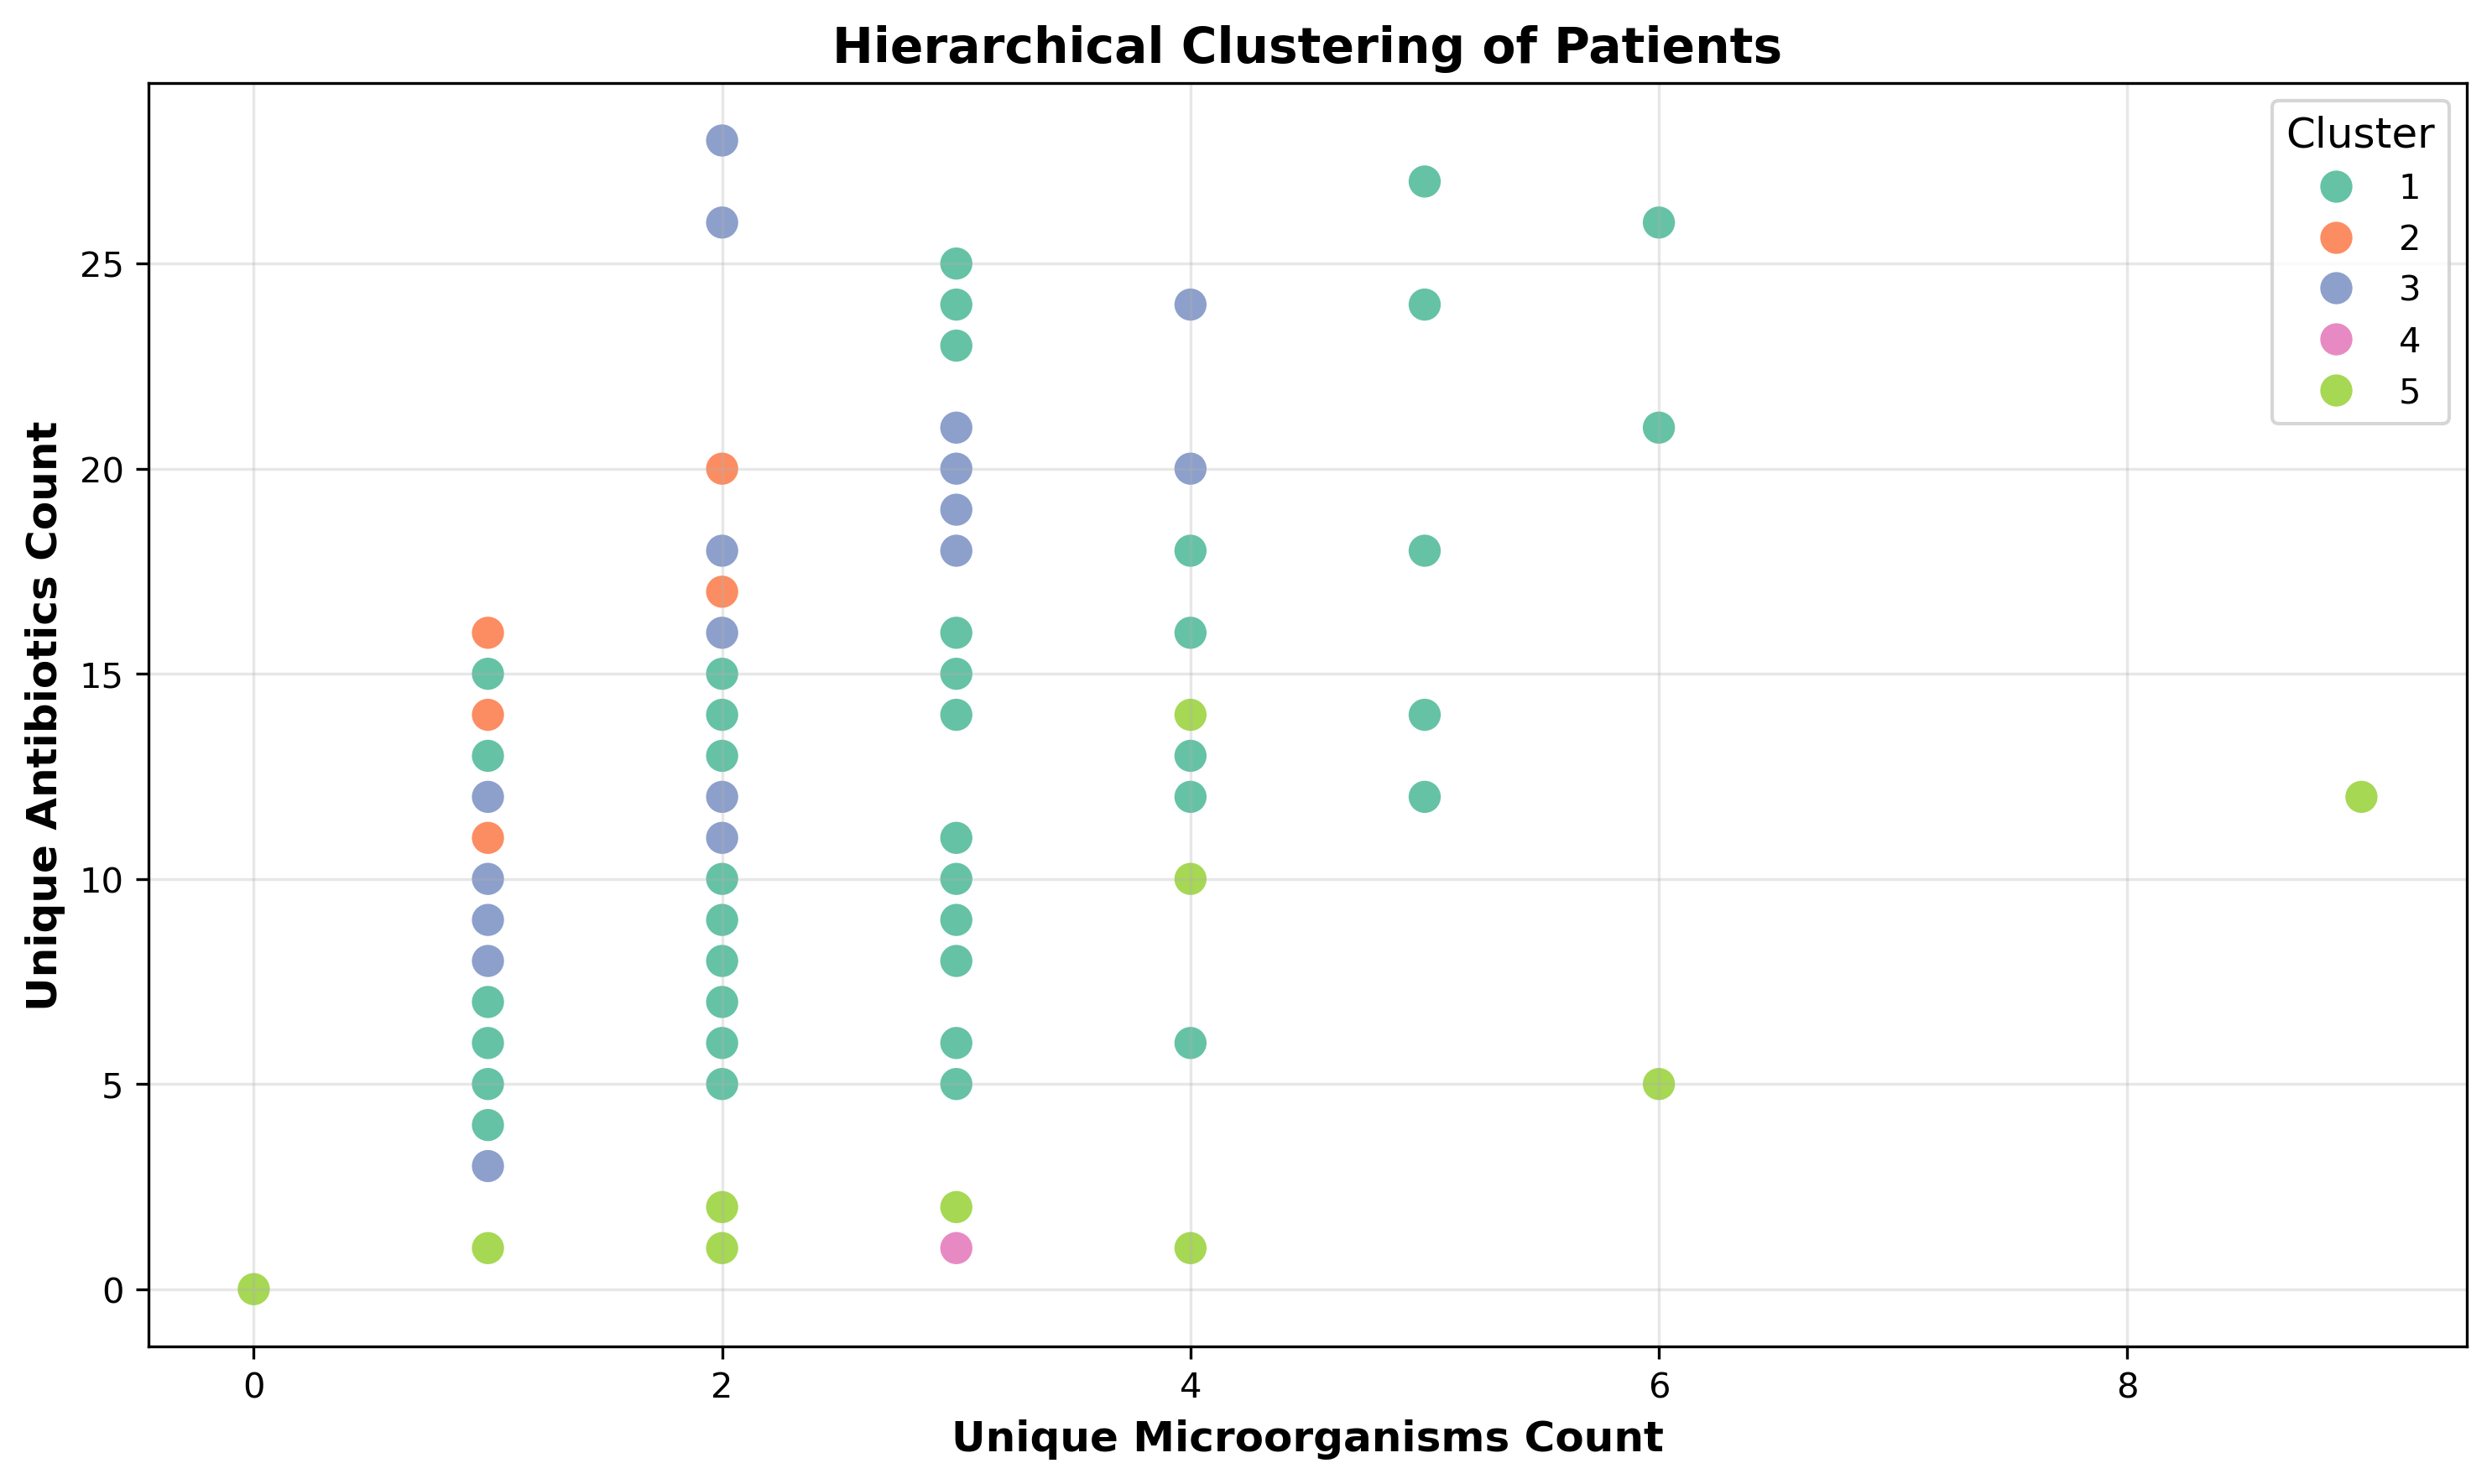

In [615]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['unique_microorganisms_count'], y=profile_df['unique_antibiotics_count'], hue=cluster_labels, palette='Set2', s=100)
plt.xlabel('Unique Microorganisms Count', fontsize=12, fontweight='bold')
plt.ylabel('Unique Antibiotics Count', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Number of lab events vs Number of abnormal lab events

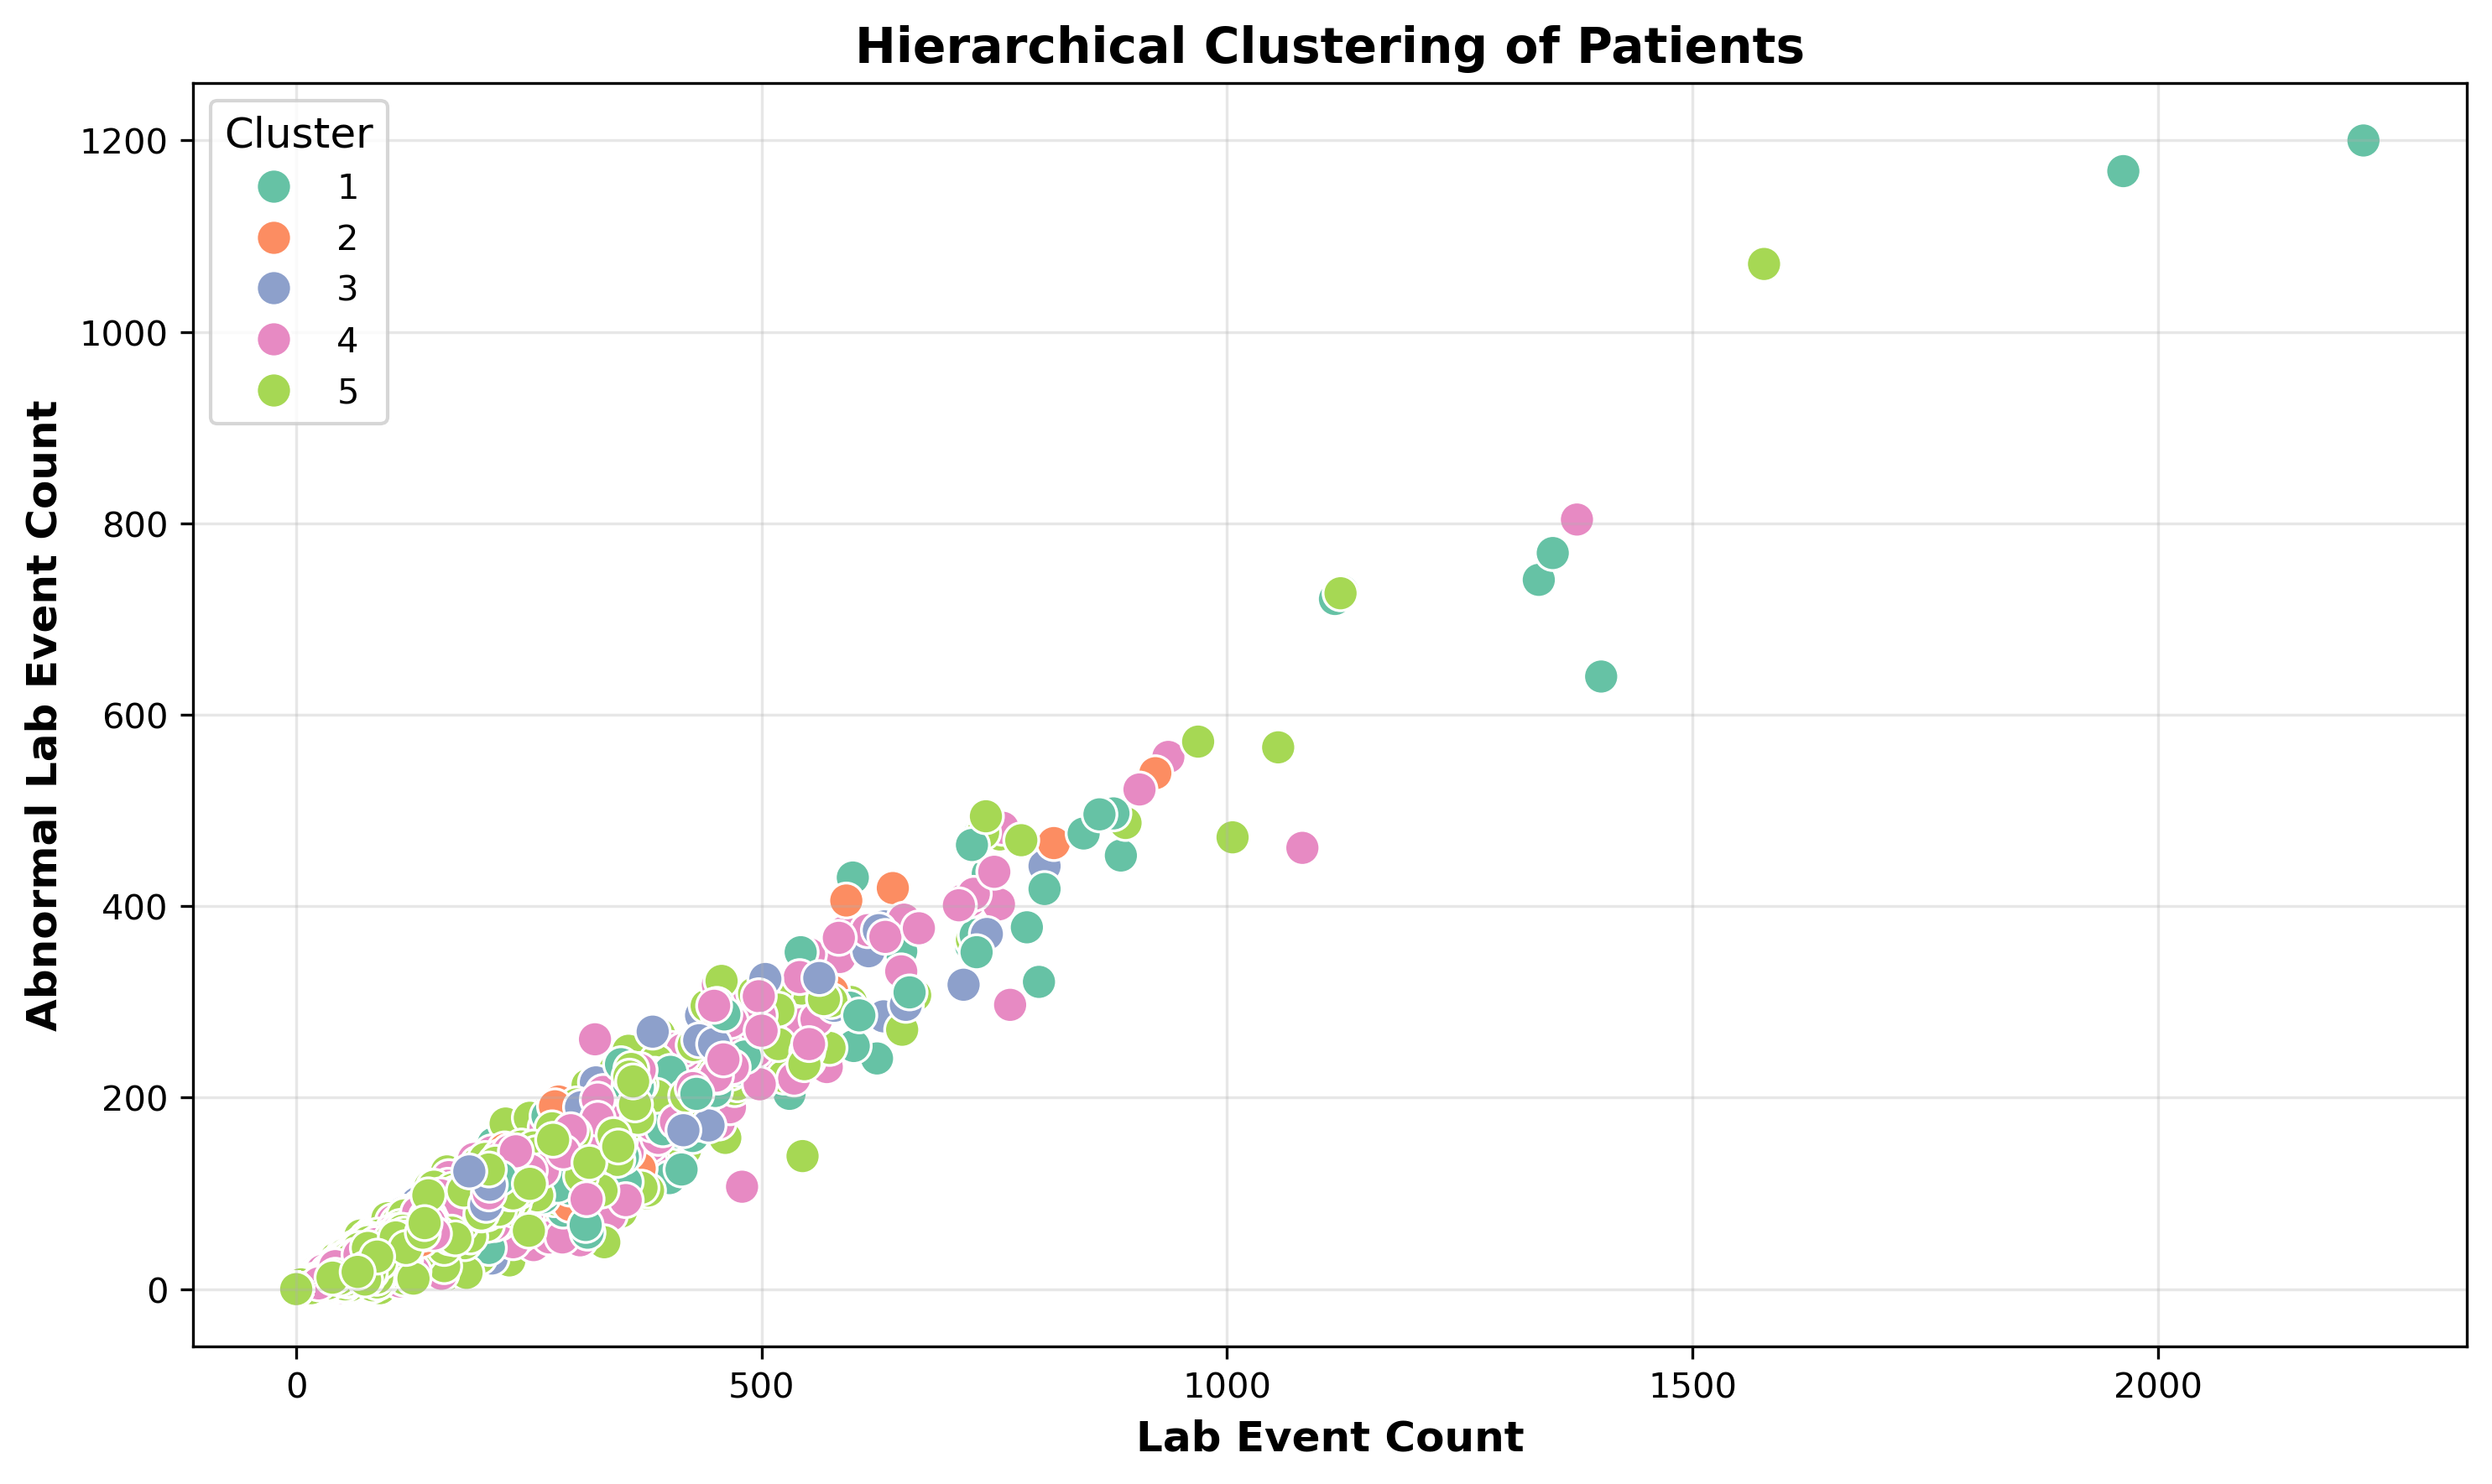

In [616]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['lab_event_count'], y=profile_df['abnormal_lab_event_count'], hue=cluster_labels, palette='Set2', s=100)
plt.xlabel('Lab Event Count', fontsize=12, fontweight='bold')
plt.ylabel('Abnormal Lab Event Count', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()